# Pricing a Structured Basket Product: HSBC 7-Year Annual Income Opportunity CD

Monte Carlo price and risks of a principal-protected certificate of deposit whose annual coupon depends on a basket of US stocks.

| Term | Value |
|---|---|
| Issuer | HSBC Bank USA, N.A. (FDIC-insured CD) |
| Trade date (Initial Fixing Date) / settlement date | 25 April 2012 / 30 April 2012 |
| Maturity | 30 April 2019, redemption at 100% of the principal |
| Interest valuation dates | 25 April 2013 to 25 April 2019, every year (payment 3 to 5 days later) |
| Reference security return | Auto Cap Rate (6.25%) if the stock is at or above its Initial Share Price, otherwise its performance floored at -30% |
| Annual coupon | max( average of the reference security returns, 0% ) |
| Reference securities | AEP, T, BIIB, KMB, LMT, MXIM, PFE, RL, MOS (Silver Wheaton, the 10th stock of the term sheet, is not in the Bloomberg data set) |

Market data as of 25 April 2012 from Bloomberg: spots, implied volatilities, correlation matrix, the 7-year Treasury rate for the drift and a USD zero-coupon curve bootstrapped from deposits, Eurodollar futures and swaps for the discounting.

In [1]:
import numpy as np
import pandas as pd
import datetime as dt
from scipy.stats import norm
from scipy.linalg import cholesky
from scipy.interpolate import interp1d
import cvxpy as cp
from pandas.tseries.offsets import BDay
from scipy.interpolate import PchipInterpolator
import matplotlib.pyplot as plt

In [2]:
valuation_dates = [
    dt.date(2013, 4, 25),
    dt.date(2014, 4, 25),
    dt.date(2015, 4, 27),
    dt.date(2016, 4, 27),
    dt.date(2017, 4, 26),
    dt.date(2018, 4, 25),
    dt.date(2019, 4, 25)
]

payment_dates = [
    dt.date(2013, 4, 30),
    dt.date(2014, 4, 30),
    dt.date(2015, 4, 30),
    dt.date(2016, 5, 2),
    dt.date(2017, 5, 1),
    dt.date(2018, 4, 30),
    dt.date(2019, 4, 30)
]

trade_date = dt.date(2012, 4, 25)  # Trade date = Initial Fixing Date (spots, vols and curve are as of this date)
settlement_date = dt.date(2012, 4, 30)  # Trade settlement date

# Risk-Free Rate (7-Year Treasury)
r = 0.013624

# Reference securities (Silver Wheaton, the 10th stock of the term sheet, is not in the Bloomberg data set)
tickers = ['AEP', 'T', 'BIIB', 'KMB', 'LMT', 'MXIM', 'PFE', 'RL', 'MOS']

# Spot Prices (from Bloomberg)
spot_prices = np.array([38.475, 23.9755, 119.094, 75.4621, 90.995,
                        27.315, 21.6938, 167.51, 53.21])

# Correlation matrix
corr_matrix = np.array([
    [1.000, -0.004, 0.304, 0.322, 0.424, 0.279, -0.248, 0.603, 0.263],
    [-0.004, 1.000, 0.072, -0.025, 0.447, -0.107, -0.556, -0.354, -0.220],
    [0.304, 0.072, 1.000, 0.773, 0.861, -0.244, 0.563, 0.707, -0.172],
    [0.322, -0.025, 0.773, 1.000, 0.783, 0.089, 0.231, 0.365, -0.597],
    [0.424, 0.447, 0.861, 0.783, 1.000, 0.047, 0.096, 0.461, -0.414],
    [0.279, -0.107, -0.244, 0.089, 0.047, 1.000, -0.392, -0.037, -0.445],
    [-0.248, -0.556, 0.563, 0.231, 0.096, -0.392, 1.000, 0.596, 0.164],
    [0.603, -0.354, 0.707, 0.365, 0.461, -0.037, 0.596, 1.000, 0.369],
    [0.263, -0.220, -0.172, -0.597, -0.414, -0.445, 0.164, 0.369, 1.000]
])

# Implied volatilities
implied_vols = np.array([20.125, 19.325, 36.631, 16.973, 22.503,
                         33.773, 22.945, 38.387, 39.492]) / 100

# Coupon terms (term sheet): each stock contributes the Auto Cap Rate if it is at or above its initial price,
# otherwise its performance floored at -30%. The coupon is the average over the basket, floored at 0%.
cap_rate = 0.0625
floor_rate = -0.30

# Seed of the random generator: the same random numbers are used for the base price and for every bump
# (common random numbers), so the risk figures measure the bump and not the Monte Carlo noise
seed = 12345678


In [3]:
def nearest_positive_definite(A):
    """
    Find the nearest positive definite matrix to A using convex optimization.
    """
    n = A.shape[0]
    X = cp.Variable((n, n), symmetric=True)
    objective = cp.Minimize(cp.norm(X - A, 'fro'))
    constraints = [X >> 0]
    problem = cp.Problem(objective, constraints)
    problem.solve()
    return X.value

def find_good_fit_cov_mat(corr_matrix, implied_vols):
    # Ensure the correlation matrix is positive definite
    # Ensure implied volatilities are strictly positive
    implied_vols = np.maximum(implied_vols, 1e-8)
    # Create a diagonal matrix with the implied volatilities
    diag_vols = np.diag(implied_vols)
    # Compute the covariance matrix
    cov_matrix = diag_vols @ corr_matrix @ diag_vols
    # Check if the covariance matrix is positive definite
    eigenvalues, _ = np.linalg.eigh(cov_matrix)
    while not np.all(eigenvalues > 0):
      # Ensure the covariance matrix is positive definite
      cov_matrix = nearest_positive_definite(cov_matrix)
      cov_matrix += np.eye(cov_matrix.shape[0]) * 1e-8
      eigenvalues, _ = np.linalg.eigh(cov_matrix)
    L = cholesky(cov_matrix, lower=True)
    return L


class BootStrap():
  def __init__(self, short_term_rates, medium_term_prices, long_term_rates, trade_date, maturity_date):
    # Short term
    self.df_short = pd.DataFrame(list(short_term_rates.items()), columns=['Maturity', 'Rate'])
    self.df_short["Time_to_Maturity"] = [1, 7, 14, 30, 60, 90, 180]
    # Medium term
    self.df_medium = pd.DataFrame(list(medium_term_prices.items()), columns=['Date', 'Price'])
    self.df_medium.Date = pd.to_datetime(self.df_medium.Date)
    self.df_medium["ZC_maturity"] = self.df_medium["Date"].shift(-1)
    self.df_medium["Time_to_Maturity"] = (self.df_medium.ZC_maturity - pd.to_datetime(trade_date)).dt.days
    self.df_medium["Rate"] = (100-self.df_medium.Price)/100
    # Long term
    self.df_long = pd.DataFrame(list(long_term_rates.items()), columns=['Date', 'Rate'])
    self.df_long["Time_to_Maturity"] = [x for x in range(2,11)]  # USSW2 ... USSW10: swaps of 2 to 10 years
    #Date
    self.trade_date = dt.datetime.strptime(trade_date,"%Y-%m-%d").date()
    self.maturity_date = dt.datetime.strptime(maturity_date,"%Y-%m-%d").date()
    #Output
    self.df_combined = None

  def ZC(self):
    # Short term
    self.df_short["ZC"] = (1+self.df_short.Rate * self.df_short.Time_to_Maturity/360)**(365/self.df_short.Time_to_Maturity) - 1
    # Medium term
    # Row i holds the futures of date i, whose rate applies from date i to date i+1 (its ZC_maturity).
    # The last futures has no following date: it is not used.
    self.df_medium = self.df_medium.dropna(subset=["Time_to_Maturity"]).reset_index(drop=True)
    self.df_medium["ZC"] = None
      # Zero rate at the start date of the first futures, from the short-term curve
    interp_func = interp1d(self.df_short["Time_to_Maturity"], self.df_short["ZC"], kind='linear', fill_value="extrapolate")
    prev_T = (self.df_medium.loc[0, "Date"] - pd.to_datetime(self.trade_date)).days
    prev_ZC = float(interp_func(prev_T))
      # Rest of the curve: each futures rate compounds the previous zero rate up to the next futures date
    for i in range(len(self.df_medium)):
      self.df_medium.loc[i, "ZC"] = (((1 + prev_ZC)**(prev_T/365)) * (1+ self.df_medium.loc[i, "Rate"]*(self.df_medium.loc[i, "Time_to_Maturity"] - prev_T)/360))**(365/self.df_medium.loc[i, "Time_to_Maturity"]) - 1
      prev_T, prev_ZC = self.df_medium.loc[i, "Time_to_Maturity"], self.df_medium.loc[i, "ZC"]
    # Long term
    self.df_long["ZC"] = None
      # 1-year zero rate from the futures strip: it discounts the first annual coupon of every swap
    interp_func = interp1d(self.df_medium["Time_to_Maturity"].astype(float), self.df_medium["ZC"].astype(float), kind='linear', fill_value="extrapolate")
    zc_by_year = {1: float(interp_func(365))}
      # Rest of the curve: bootstrap of the annual par swap rates, year after year
    for i in range(len(self.df_long)):
      n = self.df_long.loc[i, "Time_to_Maturity"]
      discount_sum = 0
      for j in range(1, n):  # Includes all the previous years
        discount_sum += (self.df_long.loc[i, "Rate"] * 100) / ((1 + zc_by_year[j]) ** j)
      zc_by_year[n] = ((1 + self.df_long.loc[i, "Rate"]) * 100 /
                                (100 - discount_sum)) ** (1 / n) - 1
      self.df_long.loc[i, "ZC"] = zc_by_year[n]

  def show_curves(self):
    # Gather all the data in one DataFrame for the plot (copies: the curve itself is not modified)
    df_short = self.df_short.assign(Source="Short term (deposits)")
    df_medium = self.df_medium.assign(Source="Medium term (Eurodollar futures)")
    df_long = self.df_long.assign(Time_to_Maturity=self.df_long["Time_to_Maturity"]*365, Source="Long term (swaps)")
    df_combined = pd.concat([df_short[["Time_to_Maturity", "ZC", "Source"]],
                            df_medium[["Time_to_Maturity", "ZC", "Source"]],
                            df_long[["Time_to_Maturity", "ZC", "Source"]]])
    # Plot the ZC curve, in years and in percent
    plt.figure(figsize=(10, 5.5))
    for (label, df_group), color in zip(df_combined.groupby("Source", sort=False), ['#2a78d6', '#eb6834', '#1baf7a']):
        plt.plot(df_group["Time_to_Maturity"]/365, df_group["ZC"].astype(float)*100, marker='o', markersize=6, linewidth=2, color=color, label=label)
    if self.df_combined is not None:
        plt.plot((self.df_combined["Time_to_Maturity"]/365).values, self.df_combined["ZC"].values*100, color='#52514e', linewidth=1, linestyle='--', label='Interpolated curve')
    plt.xlabel("Time to maturity (years)")
    plt.ylabel("Zero-coupon rate (%, annual compounding)")
    plt.title("USD zero-coupon curve as of 25 April 2012", loc='left')
    plt.legend(frameon=False)
    plt.grid(True, color='#e4e3df')
    plt.show()

  def get_one_curve(self):
    df_one = self.df_short[["Time_to_Maturity", "ZC"]].copy()
    df_one = df_one[df_one["Time_to_Maturity"] < self.df_medium["Time_to_Maturity"].iloc[0]]
    df_second = self.df_medium[["Time_to_Maturity", "ZC"]].copy()
    df_second = df_second[df_second["Time_to_Maturity"] < self.df_long["Time_to_Maturity"].iloc[0] * 365]
    df_third = self.df_long[["Time_to_Maturity", "ZC"]].copy()
    df_third["Time_to_Maturity"] *= 365
    df_one_curve = pd.concat([df_one, df_second, df_third])
    df_one_curve = df_one_curve.sort_values(by=["Time_to_Maturity"])
    df_one_curve = df_one_curve.drop_duplicates(subset=['Time_to_Maturity'], keep='first')
    self.df_combined = pd.DataFrame(columns=["Time_to_Maturity", "ZC"])
    self.df_combined["Time_to_Maturity"] = list(range(1, (self.maturity_date - self.trade_date).days + 1))
    interp_func = interp1d(df_one_curve["Time_to_Maturity"], df_one_curve["ZC"], kind='linear', fill_value="extrapolate")
    self.df_combined["ZC"] = interp_func(self.df_combined["Time_to_Maturity"])
    self.df_combined.index = [self.trade_date + dt.timedelta(days=x) for x in self.df_combined["Time_to_Maturity"]]


def construct_zc_curve(rate_bump=0.0, return_bootstrap=False):
    """
    Constructs a USD Zero-Coupon Curve using BootStrap methodology
    to ensure correct discount factors from market data.
    """
    # Define Trade and Maturity Dates
    trade_date = "2012-04-25"  # Pricing start date
    maturity_date = "2022-04-30"  # Last available swap rate maturity

    # Define Market Data
    short_term_rates = {
        dt.date(2012, 5, 1): 0.0015,    # O/N
        dt.date(2012, 5, 7): 0.001906,  # 1W
        dt.date(2012, 5, 14): 0.002115, # 2W
        dt.date(2012, 5, 30): 0.0023875, # 1M
        dt.date(2012, 7, 11): 0.0034675, # 2M
        dt.date(2012, 8, 20): 0.0046585, # 3M
        dt.date(2012, 11, 27): 0.0072940, # 6M
    }

    medium_term_prices = {
        dt.date(2012, 6, 18): 99.52,  # Eurodollar Futures
        dt.date(2012, 9, 17): 99.48,
        dt.date(2012, 12, 17): 99.46,
        dt.date(2013, 3, 18): 99.445,
        dt.date(2013, 6, 17): 99.42,
        dt.date(2013, 9, 16): 99.385,
        dt.date(2013, 12, 16): 99.33,
        dt.date(2014, 3, 17): 99.26,
    }

    long_term_rates = {
        dt.date(2014, 4, 30): 0.005575,  # Swap Rates
        dt.date(2015, 4, 30): 0.006860,
        dt.date(2016, 4, 30): 0.009005,
        dt.date(2017, 4, 30): 0.011430,
        dt.date(2018, 4, 30): 0.013895,
        dt.date(2019, 4, 30): 0.016162,
        dt.date(2020, 4, 30): 0.018060,
        dt.date(2021, 4, 30): 0.019678,
        dt.date(2022, 4, 30): 0.021075,
    }

    # Initialize BootStrap Class
    bootstrap_curve = BootStrap(short_term_rates, medium_term_prices, long_term_rates, trade_date, maturity_date)
    bootstrap_curve.ZC()  # Compute the Zero Coupon rates
    bootstrap_curve.get_one_curve()  # Construct full term structure
    # bootstrap_curve.show_curves()  # Plot the full term structure
    # **4. Apply Rate Bump**
    bootstrap_curve.df_combined["ZC"] += rate_bump  # Apply bump for risk analysis

    # Create Interpolated ZC Curve
    tenors = bootstrap_curve.df_combined.index
    rates = bootstrap_curve.df_combined["ZC"].values
    zc_curve = interp1d([(t - bootstrap_curve.trade_date).days / 365.0 for t in tenors],
                        rates, kind='linear', fill_value="extrapolate")

    if return_bootstrap:
        return zc_curve, bootstrap_curve
    return zc_curve

def simulate_gbm_paths(S0, sigma, r, valuation_dates, L, num_paths=100000, seed=None, dividend_yields=None, start_date=None):
    """ Simulates GBM paths with correlation, from the trade date to each valuation date (ACT/365) """
    num_steps = len(valuation_dates)
    start_date = trade_date if start_date is None else start_date
    times = np.array([(d - start_date).days for d in valuation_dates]) / 365.0
    dt_years = np.diff(np.concatenate([[0.0], times]))
    q = np.zeros(len(S0)) if dividend_yields is None else np.asarray(dividend_yields)

    # L is the Cholesky factor of the covariance matrix: dividing each row by its norm (the volatility of the asset)
    # gives the Cholesky factor of the correlation matrix, so that the volatility is applied once, through sigma
    L_corr = L / np.linalg.norm(L, axis=1, keepdims=True)

    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(size=(num_paths, num_steps, len(S0)))
    dW = np.einsum('jk,imk->imj', L_corr, Z)

    S = np.zeros((num_paths, num_steps + 1, len(S0)))
    S[:, 0, :] = S0

    for t in range(1, num_steps + 1):
        S[:, t, :] = S[:, t-1, :] * np.exp((r - q - 0.5 * sigma**2) * dt_years[t-1] +
                                           sigma * np.sqrt(dt_years[t-1]) * dW[:, t-1, :])
    return S

def compute_payoff(S, valuation_dates, principal=100, cap_rate=0.0625, floor_rate=-0.30, initial_prices=None):
    """Computes the correct interest payments on each valuation date using the given formula."""
    num_paths, num_steps, N = S.shape  # Paths, valuation dates, assets
    payoffs = np.zeros((num_paths, num_steps - 1))

    S0 = S[:, 0, :] if initial_prices is None else np.asarray(initial_prices)  # Initial Share Prices, fixed on the Initial Fixing Date

    for t in range(num_steps - 1):  # Loop over valuation dates
        ST = S[:, t+1, :]  # Stock prices at time T

        # Apply f(S_i(T), S_i(0)) formula
        f_values = np.where(ST >= S0, cap_rate, np.maximum(ST / S0 - 1, floor_rate))

        # Compute basket payoff: average across stocks, floored at 0
        basket_payoff = np.maximum(np.mean(f_values, axis=1), 0)

        # Compute interest payment: Principal * basket payoff
        payoffs[:, t] = principal * basket_payoff

    return payoffs

def discount_payoffs(payoffs, valuation_dates, payment_dates, rate_bump=0.0, principal=100):
    """Discounts the interest payoffs and includes final principal repayment correctly."""
    rate_curve = construct_zc_curve(rate_bump)  # Get the original rate curve
    payment_times = np.array([(p - trade_date).days / 365.0 for p in payment_dates])
    settlement_time = (settlement_date - trade_date).days / 365.0

    # Discount factors of annually compounded zero rates, from each payment date back to the settlement date
    # (the date on which the CD is paid for at the issue price)
    DF = (1 + rate_curve(payment_times)) ** (-payment_times) / (1 + rate_curve(settlement_time)) ** (-settlement_time)  # Shape (7,)

    # Reshape DF to match payoffs for proper broadcasting
    DF_interest = DF.reshape(1, -1)  # (1, 7) so it broadcasts correctly with (10000, 7)

    # Discounted sum of interest payments
    PV_interest = np.sum(payoffs * DF_interest, axis=1)

    # Discounted principal repayment at final payment date
    PV_principal = principal * DF[-1]

    # Total present value
    PV = PV_interest + PV_principal

    return PV


def compute_monte_carlo_price(S0, sigma, r, valuation_dates, payment_dates, L,
                              rate_bump=0.0, num_paths=100000, principal=100, seed=None, dividend_yields=None,
                              return_std_err=False, initial_prices=None):
    """ Full Monte Carlo pricing pipeline with interest payments and principal repayment """

    # Simulate GBM price paths (a parallel rate bump moves the drift as well as the discount curve)
    S = simulate_gbm_paths(S0, sigma, r + rate_bump, valuation_dates, L, num_paths=num_paths, seed=seed,
                           dividend_yields=dividend_yields)

    # Compute periodic interest payments
    payoffs = compute_payoff(S, valuation_dates, principal, cap_rate=cap_rate, floor_rate=floor_rate, initial_prices=initial_prices)

    # Discount payoffs including final principal repayment
    if rate_bump != 0.0:
      PV = discount_payoffs(payoffs, valuation_dates, payment_dates, rate_bump=rate_bump)
    else:
      PV = discount_payoffs(payoffs, valuation_dates, payment_dates)

    # Compute final price
    price = np.mean(PV)

    if return_std_err:
        return price, PV.std(ddof=1) / np.sqrt(num_paths)
    return price


def analyze_stock_price_bump(S0, sigma, r, valuation_dates, payment_dates, L, base_price=None, seed=None, dividend_yields=None, names=None,
                             num_paths=100000):
    """
    Computes the impact of a +1% / -1% bump in each stock price separately.
    Returns a 2x9 matrix where:
        - First row contains the new prices after a +1% bump.
        - Second row contains the new prices after a -1% bump.
        - Each column corresponds to one of the 9 stocks.
    """
    if base_price is None:
      base_price = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                           payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)

    num_stocks = len(S0)
    price_matrix = np.zeros((2, num_stocks))  # 2 rows (up/down), 9 columns (stocks)

    for i in range(num_stocks):
        # Copy S0 and bump only the i-th stock
        S0_up = S0.copy()
        S0_down = S0.copy()

        S0_up[i] *= 1.01  # +1% bump
        S0_down[i] *= 0.99  # -1% bump

        # Compute new prices with bumped stock
        # The Initial Share Prices are fixings: they stay at their initial level when the spot is bumped
        price_up = compute_monte_carlo_price(S0_up, sigma, r, valuation_dates,
                                             payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields, initial_prices=S0)
        price_down = compute_monte_carlo_price(S0_down, sigma, r, valuation_dates,
                                               payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields, initial_prices=S0)

        # Store results
        price_matrix[0, i] = price_up
        price_matrix[1, i] = price_down

    # Compute the difference matrix (Price impact - Base Price)
    diff_matrix = price_matrix - base_price

    print("Stock Price Bump Analysis (+1% / -1%):")
    print(pd.DataFrame(diff_matrix, index=["+1%", "-1%"],
                       columns=names if names is not None else [f"Stock {i+1}" for i in range(num_stocks)]))
    print(f"Base price : {base_price}")
    print("###########################")
    return diff_matrix


def analyze_volatility_bump(S0, sigma, r, valuation_dates, payment_dates, L, base_price=None, seed=None, dividend_yields=None, names=None,
                            num_paths=100000):
    """
    Computes the impact of a +1% / -1% bump in each stock's volatility separately.
    Returns a 2x9 matrix where:
        - First row contains the new prices after a +1% absolute bump in volatility.
        - Second row contains the new prices after a -1% absolute bump in volatility.
    """
    num_stocks = len(sigma)

    if base_price is None:
      base_price = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                           payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)

    # Create matrices for bumped volatilities
    sigma_up = sigma[:, np.newaxis] + 0.01 * np.eye(num_stocks)  # +1% absolute bump
    sigma_down = np.maximum(sigma[:, np.newaxis] - 0.01 * np.eye(num_stocks), 0.01)  # -1% bump, floored at 1%

    # Compute Monte Carlo prices for all bumps
    price_up = np.array([
        compute_monte_carlo_price(S0, sigma_up[:, i], r, valuation_dates, payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)
        for i in range(num_stocks)
    ])

    price_down = np.array([
        compute_monte_carlo_price(S0, sigma_down[:, i], r, valuation_dates, payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)
        for i in range(num_stocks)
    ])

    # Create the result matrix
    price_matrix = np.vstack([price_up, price_down])

    # Compute the difference matrix (Price impact - Base Price)
    diff_matrix = price_matrix - base_price

    print("Volatility Bump Analysis (+1% / -1%):")
    print(pd.DataFrame(diff_matrix, index=["+1%", "-1%"],
                       columns=names if names is not None else [f"Stock {i+1}" for i in range(num_stocks)]))
    print(f"Base price : {base_price}")
    print("###########################")
    return diff_matrix

def analyze_correlation_bump(S0, sigma, r, correlation_matrix, valuation_dates, payment_dates, L, price_base=None, seed=None, dividend_yields=None,
                             num_paths=100000):
    """Computes impact of +/-10% bump in the correlation matrix on Monte Carlo price."""
    if price_base is None:
      price_base = compute_monte_carlo_price(S0, sigma, r, valuation_dates, payment_dates, L,
                                           num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)


    def shock_correlation_matrix(corr_matrix, shock_factor):
        """Apply shock to correlation matrix while keeping diagonals 1 and ensuring validity."""
        corr_shocked = corr_matrix + shock_factor  # Apply shock
        np.fill_diagonal(corr_shocked, 1.0)  # Ensure diagonal remains 1
        corr_shocked = np.clip(corr_shocked, -1, 1)  # Ensure all values remain in [-1, 1]

        # Ensure matrix is positive definite
        corr_shocked = nearest_positive_definite(corr_shocked)
        return corr_shocked

    # +10% Shock
    corr_up = shock_correlation_matrix(correlation_matrix, 0.10)
    L_up = find_good_fit_cov_mat(corr_up, sigma)
    price_up = compute_monte_carlo_price(S0, sigma, r, valuation_dates, payment_dates, L_up,
                                         num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)

    # -10% Shock
    corr_down = shock_correlation_matrix(correlation_matrix, -0.10)
    L_down = find_good_fit_cov_mat(corr_down, sigma)
    price_down = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                           payment_dates, L_down, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)

    print(f"Impact of Correlation Bump (+10%): {price_up:.4f} | Δ = {price_up - price_base:.4f}")
    print(f"Impact of Correlation Bump (-10%): {price_down:.4f} | Δ = {price_down - price_base:.4f}")
    print(f"Base price : {price_base}")
    print("###########################")

def analyze_interest_rate_bump(S0, sigma, r, valuation_dates, payment_dates, L, price_base=None, num_paths=100000, seed=None, dividend_yields=None):
    """Computes impact of +/-10 basis points bump in interest rates on Monte Carlo price."""
    if price_base is None:
      price_base = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                           payment_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)


    price_up = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                         payment_dates, L, rate_bump=0.0010, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)


    price_down = compute_monte_carlo_price(S0, sigma, r, valuation_dates,
                                           payment_dates, L, rate_bump=-0.0010,num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)

    print(f"Impact of Interest Rate Bump (+10bps): {price_up:.4f} | Δ = {price_up - price_base:.4f}")
    print(f"Impact of Interest Rate Bump (-10bps): {price_down:.4f} | Δ = {price_down - price_base:.4f}")
    print(f"Base price : {price_base}")
    print("###########################")


In [4]:
L = find_good_fit_cov_mat(corr_matrix, implied_vols)
price, std_err = compute_monte_carlo_price(spot_prices, implied_vols, r,
                                  valuation_dates, payment_dates, L, num_paths=300000, seed=seed, return_std_err=True)
print(f"Monte Carlo Price: {price:.4f} (standard error {std_err:.4f}, 95% confidence interval {price - 1.96*std_err:.4f} - {price + 1.96*std_err:.4f})")

Monte Carlo Price: 90.2053 (standard error 0.0043, 95% confidence interval 90.1970 - 90.2137)


In [5]:
# Every revaluation uses the same number of paths and the same random numbers as the base price
stock_bumps = analyze_stock_price_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, base_price=price, seed=seed, names=tickers, num_paths=300000)
vol_bumps = analyze_volatility_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, base_price=price, seed=seed, names=tickers, num_paths=300000)
analyze_correlation_bump(spot_prices, implied_vols, r, corr_matrix, valuation_dates, payment_dates, L, price_base=price, seed=seed, num_paths=300000)
analyze_interest_rate_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, price_base=price, seed=seed, num_paths=300000)

Stock Price Bump Analysis (+1% / -1%):
          AEP         T      BIIB       KMB       LMT      MXIM       PFE  \
+1%  0.009759  0.033500  0.005324  0.019438  0.005566  0.021146  0.025225   
-1% -0.010310 -0.033797 -0.005922 -0.020529 -0.006410 -0.021225 -0.025800   

           RL      MOS  
+1%  0.002415  0.02058  
-1% -0.002593 -0.02039  
Base price : 90.20534177378002
###########################


Volatility Bump Analysis (+1% / -1%):
          AEP         T      BIIB       KMB       LMT      MXIM       PFE  \
+1% -0.005095 -0.026911 -0.003103 -0.012707 -0.002443 -0.016531 -0.018147   
-1%  0.005088  0.028725  0.002849  0.013224  0.002292  0.017425  0.018900   

           RL       MOS  
+1% -0.001244 -0.016355  
-1%  0.001318  0.017036  
Base price : 90.20534177378002
###########################


Impact of Correlation Bump (+10%): 91.2553 | Δ = 1.0499
Impact of Correlation Bump (-10%): 89.4540 | Δ = -0.7514
Base price : 90.20534177378002
###########################


Impact of Interest Rate Bump (+10bps): 89.6275 | Δ = -0.5779
Impact of Interest Rate Bump (-10bps): 90.7891 | Δ = 0.5837
Base price : 90.20534177378002
###########################


## Validation and analysis

The cells below check the inputs of the pricer (zero-coupon curve, simulated dynamics), split the price into the bond and the coupons, add the dividends implied by the Bloomberg forwards, and measure how the price depends on the volatility, the correlation and the number of paths. They only reuse the functions above.

### USD zero-coupon curve

Deposits up to the first Eurodollar futures date, then the futures strip, then the annual par swaps of 2 to 10 years bootstrapped year after year. The discount factors of the payment dates are taken back to the settlement date, on which the CD is paid for.

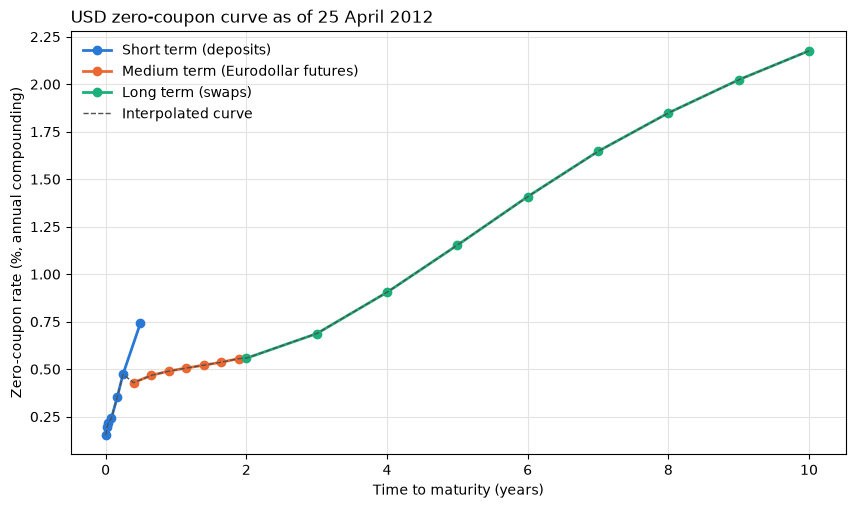

Payment date  Years from trade date Zero rate  Discount factor
  2013-04-30                  1.014   0.4975%         0.995007
  2014-04-30                  2.014   0.5594%         0.988853
  2015-04-30                  3.014   0.6900%         0.979514
  2016-05-02                  4.022   0.9099%         0.964250
  2017-05-01                  5.019   1.1576%         0.943892
  2018-04-30                  6.016   1.4122%         0.919116
  2019-04-30                  7.016   1.6499%         0.891550

Repricing of the par swaps with the bootstrapped curve (should be 100):
   2y swap at 0.5575%: 100.000000
   3y swap at 0.6860%: 100.000000
   4y swap at 0.9005%: 100.000000
   5y swap at 1.1430%: 100.000000
   6y swap at 1.3895%: 100.000000
   7y swap at 1.6162%: 100.000000
   8y swap at 1.8060%: 100.000000
   9y swap at 1.9678%: 100.000000
  10y swap at 2.1075%: 100.000000


In [6]:
import matplotlib.pyplot as plt

zc_curve, bootstrap_curve = construct_zc_curve(return_bootstrap=True)
bootstrap_curve.show_curves()
t_pay = np.array([(p - trade_date).days / 365.0 for p in payment_dates])
t_settle = (settlement_date - trade_date).days / 365.0
df_pay = (1 + zc_curve(t_pay)) ** (-t_pay) / (1 + zc_curve(t_settle)) ** (-t_settle)
curve_table = pd.DataFrame({"Payment date": payment_dates, "Years from trade date": t_pay.round(3),
                            "Zero rate": [f"{z:.4%}" for z in zc_curve(t_pay)], "Discount factor": df_pay.round(6)})
print(curve_table.to_string(index=False))
swaps = bootstrap_curve.df_long
print("\nRepricing of the par swaps with the bootstrapped curve (should be 100):")
zc_years = {1: float(zc_curve(1.0))}
zc_years.update({int(n): float(z) for n, z in zip(swaps["Time_to_Maturity"], swaps["ZC"])})
for n, s in zip(swaps["Time_to_Maturity"], swaps["Rate"]):
    pv = sum(100 * s / (1 + zc_years[j]) ** j for j in range(1, n)) + 100 * (1 + s) / (1 + zc_years[n]) ** n
    print(f"  {n:2d}y swap at {s:.4%}: {pv:.6f}")

### Checks of the simulated dynamics

Under the risk-neutral measure the discounted mean of each stock must equal its forward, and the simulated log-returns must have the input volatilities and correlations.

In [7]:
S_check = simulate_gbm_paths(spot_prices, implied_vols, r, valuation_dates, L, num_paths=200000, seed=seed)
t_first = (valuation_dates[0] - trade_date).days / 365.0
t_last = (valuation_dates[-1] - trade_date).days / 365.0
log_ret = np.log(S_check[:, 1, :] / S_check[:, 0, :])
checks = pd.DataFrame({
    "E[S(T)] / forward": S_check[:, -1, :].mean(axis=0) / (spot_prices * np.exp(r * t_last)),
    "input vol": implied_vols,
    "simulated vol": log_ret.std(axis=0) / np.sqrt(t_first),
}, index=tickers)
print(checks.round(4).to_string())
print("\nLargest gap between simulated and input correlations:", np.abs(np.corrcoef(log_ret.T) - corr_matrix).max().round(4))
print("Smallest eigenvalue of the Bloomberg correlation matrix:", np.linalg.eigvalsh(corr_matrix).min().round(5),
      "(not positive definite: the nearest positive definite covariance is used)")
del S_check

      E[S(T)] / forward  input vol  simulated vol
AEP              0.9992     0.2013         0.2014
T                0.9994     0.1932         0.1936
BIIB             0.9964     0.3663         0.3656
KMB              0.9991     0.1697         0.1697
LMT              0.9981     0.2250         0.2250
MXIM             1.0021     0.3377         0.3377
PFE              0.9990     0.2294         0.2290
RL               0.9975     0.3839         0.3836
MOS              1.0019     0.3949         0.3953

Largest gap between simulated and input correlations: 0.0036
Smallest eigenvalue of the Bloomberg correlation matrix: -0.00081 (not positive definite: the nearest positive definite covariance is used)


### Dividends implied by the Bloomberg forwards

The base case above simulates the stocks without dividends. The coupons of the CD depend on the price performance of the stocks, without dividends, so the expected dividends lower the coupons. The Bloomberg screens give, for each stock, a forward to 30 April 2019 (2,561 days, USD rate 1.279% with semi-annual compounding); the continuous dividend yield $q_i$ that reproduces each forward is used below.

In [8]:
forwards_bloomberg = np.array([25.6863, 12.0728, 130.225, 56.0066, 52.638, 20.5399, 15.2367, 168.6774, 52.2304])
r_bloomberg = 2 * np.log(1 + 0.01279 / 2)
T_bloomberg = 2561 / 365
dividend_yields = np.maximum(r_bloomberg - np.log(forwards_bloomberg / spot_prices) / T_bloomberg, 0.0)
print(pd.DataFrame({"spot": spot_prices, "forward 2019": forwards_bloomberg, "implied dividend yield": [f"{q:.2%}" for q in dividend_yields]},
                   index=tickers).to_string())
price_div, std_err_div = compute_monte_carlo_price(spot_prices, implied_vols, r, valuation_dates, payment_dates, L,
                                                   num_paths=300000, seed=seed, dividend_yields=dividend_yields, return_std_err=True)
print(f"\nPrice without dividends: {price:.4f}   Price with the implied dividends: {price_div:.4f} (standard error {std_err_div:.4f})")

          spot  forward 2019 implied dividend yield
AEP    38.4750       25.6863                  7.03%
T      23.9755       12.0728                 11.05%
BIIB  119.0940      130.2250                  0.00%
KMB    75.4621       56.0066                  5.52%
LMT    90.9950       52.6380                  9.08%
MXIM   27.3150       20.5399                  5.34%
PFE    21.6938       15.2367                  6.31%
RL    167.5100      168.6774                  1.18%
MOS    53.2100       52.2304                  1.54%



Price without dividends: 90.2053   Price with the implied dividends: 89.2627 (standard error 0.0009)


In [9]:
analyze_stock_price_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, base_price=price_div, seed=seed, dividend_yields=dividend_yields, names=tickers, num_paths=300000)
analyze_volatility_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, base_price=price_div, seed=seed, dividend_yields=dividend_yields, names=tickers, num_paths=300000)
analyze_correlation_bump(spot_prices, implied_vols, r, corr_matrix, valuation_dates, payment_dates, L, price_base=price_div, seed=seed, dividend_yields=dividend_yields, num_paths=300000)
analyze_interest_rate_bump(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, price_base=price_div, seed=seed, dividend_yields=dividend_yields, num_paths=300000)

Stock Price Bump Analysis (+1% / -1%):
          AEP         T      BIIB       KMB       LMT      MXIM       PFE  \
+1%  0.001815  0.006819  0.000144  0.004675  0.001776  0.004166  0.005528   
-1% -0.001923 -0.006441 -0.000176 -0.004968 -0.001822 -0.004166 -0.005482   

           RL       MOS  
+1%  0.000027  0.004000  
-1% -0.000034 -0.004099  
Base price : 89.26266370930652
###########################


Volatility Bump Analysis (+1% / -1%):
          AEP         T      BIIB       KMB       LMT      MXIM       PFE  \
+1%  0.000241  0.000002 -0.000042  0.000022  0.000413 -0.001289 -0.001011   
-1% -0.000264  0.000097  0.000036 -0.000218 -0.000454  0.001335  0.000982   

           RL       MOS  
+1% -0.000005 -0.001749  
-1%  0.000004  0.001740  
Base price : 89.26266370930652
###########################


Impact of Correlation Bump (+10%): 89.5305 | Δ = 0.2678
Impact of Correlation Bump (-10%): 89.1653 | Δ = -0.0974
Base price : 89.26266370930652
###########################


Impact of Interest Rate Bump (+10bps): 88.6544 | Δ = -0.6083
Impact of Interest Rate Bump (-10bps): 89.8758 | Δ = 0.6132
Base price : 89.26266370930652
###########################


### What the investor buys: a zero-coupon bond and a strip of capped coupons

The price splits into the discounted principal, which does not depend on the stocks, and the discounted coupons. The table shows, for each year, the expected coupon, the probability of a zero coupon and the probability of the maximum coupon of 6.25%.

--- no dividends: principal 89.155 + coupons 1.050 = 90.205 | issue price 100 - fair value = 9.79 points
payment date  expected coupon (%)  P(coupon = 0)  P(coupon = 6.25%)  discounted expected coupon
  2013-04-30               0.3591         0.8042             0.0011                      0.3573
  2014-04-30               0.2111         0.8729             0.0008                      0.2087
  2015-04-30               0.1510         0.9043             0.0005                      0.1479
  2016-05-02               0.1169         0.9241             0.0004                      0.1127
  2017-05-01               0.0949         0.9369             0.0003                      0.0895
  2018-04-30               0.0796         0.9464             0.0002                      0.0732
  2019-04-30               0.0684         0.9539             0.0002                      0.0610


--- implied dividends: principal 89.155 + coupons 0.108 = 89.263 | issue price 100 - fair value = 10.74 points
payment date  expected coupon (%)  P(coupon = 0)  P(coupon = 6.25%)  discounted expected coupon
  2013-04-30               0.0872         0.9293                0.0                      0.0867
  2014-04-30               0.0147         0.9854                0.0                      0.0146
  2015-04-30               0.0040         0.9959                0.0                      0.0039
  2016-05-02               0.0015         0.9984                0.0                      0.0014
  2017-05-01               0.0008         0.9992                0.0                      0.0007
  2018-04-30               0.0003         0.9997                0.0                      0.0003
  2019-04-30               0.0001         0.9999                0.0                      0.0001


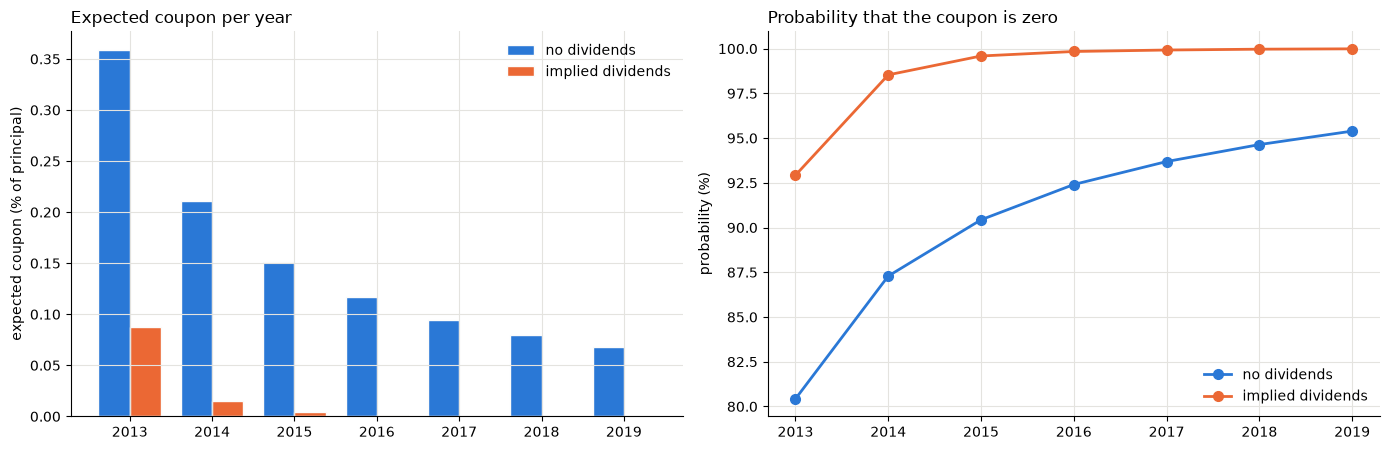

In [10]:
def coupon_statistics(dividend_yields=None, num_paths=300000):
    S = simulate_gbm_paths(spot_prices, implied_vols, r, valuation_dates, L, num_paths=num_paths, seed=seed, dividend_yields=dividend_yields)
    coupons = compute_payoff(S, valuation_dates, principal=100, cap_rate=cap_rate, floor_rate=floor_rate)
    rate_curve = construct_zc_curve()
    t_pay = np.array([(p - trade_date).days / 365.0 for p in payment_dates])
    t_settle = (settlement_date - trade_date).days / 365.0
    DF = (1 + rate_curve(t_pay)) ** (-t_pay) / (1 + rate_curve(t_settle)) ** (-t_settle)
    table = pd.DataFrame({"payment date": payment_dates,
                          "expected coupon (%)": coupons.mean(axis=0),
                          "P(coupon = 0)": (coupons <= 1e-12).mean(axis=0),
                          "P(coupon = 6.25%)": (coupons >= 100 * cap_rate - 1e-9).mean(axis=0),
                          "discounted expected coupon": coupons.mean(axis=0) * DF})
    return table, 100 * DF[-1]

decomposition = {}
for label, q in [("no dividends", None), ("implied dividends", dividend_yields)]:
    table, pv_principal = coupon_statistics(q)
    decomposition[label] = table
    pv_coupons = table["discounted expected coupon"].sum()
    print(f"--- {label}: principal {pv_principal:.3f} + coupons {pv_coupons:.3f} = {pv_principal + pv_coupons:.3f}"
          f" | issue price 100 - fair value = {100 - pv_principal - pv_coupons:.2f} points")
    print(table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
years = [d.year for d in payment_dates]
w = 0.38
for k, ((label, table), color) in enumerate(zip(decomposition.items(), ["#2a78d6", "#eb6834"])):
    axes[0].bar(np.arange(7) + (k - 0.5) * w, table["expected coupon (%)"], w, color=color, edgecolor="#fcfcfb", label=label)
    axes[1].plot(years, table["P(coupon = 0)"] * 100, marker="o", markersize=7, linewidth=2, color=color, label=label)
axes[0].set_xticks(np.arange(7))
axes[0].set_xticklabels(years)
axes[0].set_ylabel("expected coupon (% of principal)")
axes[0].set_title("Expected coupon per year", loc="left")
axes[1].set_ylabel("probability (%)")
axes[1].set_title("Probability that the coupon is zero", loc="left")
for a in axes:
    a.legend(frameon=False)
    a.grid(True, color="#e4e3df")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Volatility and correlation

Price as a function of a common scaling of the nine volatilities and of a uniform shift of all the correlations (made positive definite as in the correlation bump above), with and without dividends. Same random numbers everywhere.

no dividends: price by vol scale {0.5: np.float64(93.942), 0.75: np.float64(91.253), 1.0: np.float64(90.194), 1.25: np.float64(89.716), 1.5: np.float64(89.477)}
no dividends: price by correlation shift {-0.2: np.float64(89.234), -0.1: np.float64(89.454), 0.0: np.float64(90.194), 0.1: np.float64(91.241), 0.2: np.float64(92.314), 0.3: np.float64(93.282)}
implied dividends: price by vol scale {0.5: np.float64(89.315), 0.75: np.float64(89.293), 1.0: np.float64(89.26), 1.25: np.float64(89.234), 1.5: np.float64(89.214)}
implied dividends: price by correlation shift {-0.2: np.float64(89.156), -0.1: np.float64(89.166), 0.0: np.float64(89.26), 0.1: np.float64(89.528), 0.2: np.float64(89.896), 0.3: np.float64(90.32)}


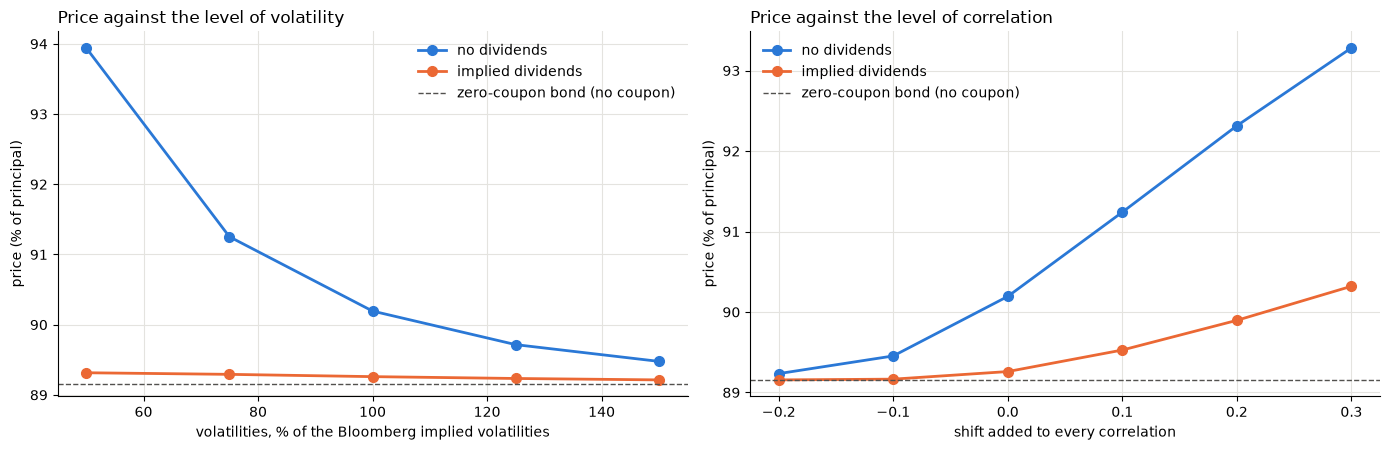

In [11]:
def shocked_cholesky(shift):
    corr = corr_matrix + shift
    np.fill_diagonal(corr, 1.0)
    corr = np.clip(corr, -1, 1)
    if shift != 0:
        corr = nearest_positive_definite(corr)
    return find_good_fit_cov_mat(corr, implied_vols)

vol_scales = [0.5, 0.75, 1.0, 1.25, 1.5]
corr_shifts = [-0.2, -0.1, 0.0, 0.1, 0.2, 0.3]
sensitivity = {}
for label, q in [("no dividends", None), ("implied dividends", dividend_yields)]:
    sensitivity[label] = (
        [compute_monte_carlo_price(spot_prices, implied_vols * k, r, valuation_dates, payment_dates, L, num_paths=100000, seed=seed, dividend_yields=q) for k in vol_scales],
        [compute_monte_carlo_price(spot_prices, implied_vols, r, valuation_dates, payment_dates, shocked_cholesky(c), num_paths=100000, seed=seed, dividend_yields=q) for c in corr_shifts])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for (label, (by_vol, by_corr)), color in zip(sensitivity.items(), ["#2a78d6", "#eb6834"]):
    axes[0].plot(np.array(vol_scales) * 100, by_vol, marker="o", markersize=7, linewidth=2, color=color, label=label)
    axes[1].plot(corr_shifts, by_corr, marker="o", markersize=7, linewidth=2, color=color, label=label)
    print(f"{label}: price by vol scale {dict(zip(vol_scales, np.round(by_vol, 3)))}")
    print(f"{label}: price by correlation shift {dict(zip(corr_shifts, np.round(by_corr, 3)))}")
axes[0].set_xlabel("volatilities, % of the Bloomberg implied volatilities")
axes[0].set_title("Price against the level of volatility", loc="left")
axes[1].set_xlabel("shift added to every correlation")
axes[1].set_title("Price against the level of correlation", loc="left")
for a in axes:
    a.axhline(100 * (1 + zc_curve(t_pay[-1])) ** (-t_pay[-1]) / (1 + zc_curve(t_settle)) ** (-t_settle), color="#52514e", linestyle="--", linewidth=1, label="zero-coupon bond (no coupon)")
    a.set_ylabel("price (% of principal)")
    a.legend(frameon=False)
    a.grid(True, color="#e4e3df")
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Convergence

Price and 95% confidence interval for an increasing number of paths (no dividends, same seed).

  paths   price  standard error
  10000 90.1928          0.0232
  30000 90.1788          0.0132
 100000 90.1939          0.0073
 300000 90.2053          0.0043
1000000 90.2064          0.0023


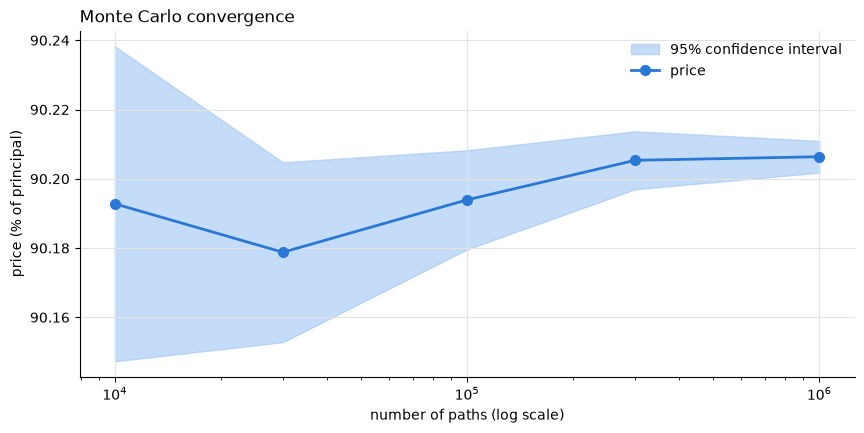

In [12]:
convergence = []
for n in [10000, 30000, 100000, 300000, 1000000]:
    p, se = compute_monte_carlo_price(spot_prices, implied_vols, r, valuation_dates, payment_dates, L, num_paths=n, seed=seed, return_std_err=True)
    convergence.append([n, p, se])
convergence = pd.DataFrame(convergence, columns=["paths", "price", "standard error"])
print(convergence.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(convergence["paths"], convergence["price"] - 1.96 * convergence["standard error"],
                convergence["price"] + 1.96 * convergence["standard error"], color="#9ec5f4", alpha=0.6, label="95% confidence interval")
ax.plot(convergence["paths"], convergence["price"], marker="o", markersize=7, linewidth=2, color="#2a78d6", label="price")
ax.set_xscale("log")
ax.set_xlabel("number of paths (log scale)")
ax.set_ylabel("price (% of principal)")
ax.set_title("Monte Carlo convergence", loc="left")
ax.legend(frameon=False)
ax.grid(True, color="#e4e3df")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Conclusions

* **Fair value.** 90.21% of the principal without dividends and 89.26% with the dividends implied by the Bloomberg forwards, against an issue price of 100%: the investor pays 9.8 to 10.7 points above the value of what he receives.
* **The CD is almost a zero-coupon bond.** The discounted principal is worth 89.16. The seven coupons add 1.05 points without dividends and 0.11 with dividends. The coupon is zero in 80% to 95% of the years without dividends and in 93% to 100% with them, and the maximum coupon of 6.25% (all nine stocks above their initial price) has a probability of about 0.1% or less.
* **Why the coupons are worth so little.** Each stock contributes at most +6.25% but can contribute down to -30%, and the coupon is the average floored at 0%. The dispersion of nine stocks over several years almost always pulls the average below zero, and more so every year (the expected coupon falls from 0.36% in 2013 to 0.07% in 2019 without dividends). The dividends, which the coupon does not include, push the stocks down further.
* **Risks.** The CD is short volatility (higher volatility means more dispersion) and long correlation (a +10% shift of all correlations adds 1.05 points). With dividends the coupons are so far out of the money that the stock, volatility and correlation risks almost vanish, and the rate risk dominates: -0.58 to -0.61 points per +10 bp, the duration of a 7-year zero-coupon bond.